# ARM KAZR Cloud Persistence Project: Analysis of the Persistence Model

**Alec Blevins — STA 496, Fall 2026**

## Purpose

Notebook 09, `09_modeling.ipynb`, compared models. Here, we will explain the chosen model (HGB, 20 min, Persistence): where it works, where it fails, and what that implies for the next step. 

**Rules**
- Same folds and embargo as 09. Nothing here changes the model or the threshold chosen in 09. Test is used for reporting purposes only. 

| Step | Question |
|---|---|
| 1. Setup | Reproduce the 09 model exactly |
| 2. Operating points | What precision do we get at a given recall, and does it transfer to test? |
| 3. Lead time | Is the model better at imminent endings than distant ones? |
| 4. Long clouds | Is the weakness on old clouds a feature limit or a fitting limit? |
| 5. Importance | Which feature groups carry the skill, and does that differ by cloud age? |



## 1. Library Imports & Setup

In [1]:
#Lib import
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

#Path to project root containing ARM_DATA/2024-2025
_start = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in [_start, *_start.parents] if (c / "ARM_DATA" / "2024-2025").is_dir())
df = pd.read_parquet(PROJECT_ROOT / "ARM_DATA" / "2024-2025" / "modeling" / "modeling_persistence_20min_20s.parquet")

# Define features and target
FEATURES = [c for c in df.columns if c not in {"current_state", "target", "fold"}]
df["y"] = (df.target == 0).astype(int)                      # 1 = dissolved
tr, va, te = (df[df.fold == k] for k in ["train", "val", "test"])

#Helper function from before
def best_f1_threshold(y, p): 
    """Compute the threshold that maximizes the F1 score."""
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.argmax(f1)])

#Define and fit HistGradientBoostingClassifier
hgb = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300,
                                     early_stopping=True, validation_fraction=0.1, random_state=0)
hgb.fit(tr[FEATURES], tr.y)
p_va, p_te = hgb.predict_proba(va[FEATURES])[:, 1], hgb.predict_proba(te[FEATURES])[:, 1]
thr = best_f1_threshold(va.y.values, p_va)

# must match notebook 09: val PR-AUC 0.781, test PR-AUC 0.646, thr 0.315
print(round(average_precision_score(va.y, p_va), 3), round(average_precision_score(te.y, p_te), 3), round(thr, 3))

0.781 0.646 0.315


## 2. Operating Points
A single F1 cutoff hides the trade-off. Here, we will chose the threshold on **validation** to hit a target recall, then apply it unchanged to the test. 

If the validation-chosen threshold gives a different recall on test, the operating point does not transfer. 

,target_recall,thr,val_recall,val_precision,val_alarm_rate,test_recall,test_precision,test_alarm_rate
0,0.5,0.638,0.5,0.796,0.205,0.440,0.706,0.114
1,0.6,0.549,0.6,0.749,0.262,0.519,0.666,0.143
2,0.7,0.443,0.7,0.698,0.328,0.608,0.617,0.180
3,0.8,0.329,0.8,0.651,0.402,0.701,0.551,0.233
4,0.9,0.197,0.9,0.583,0.504,0.816,0.474,0.315


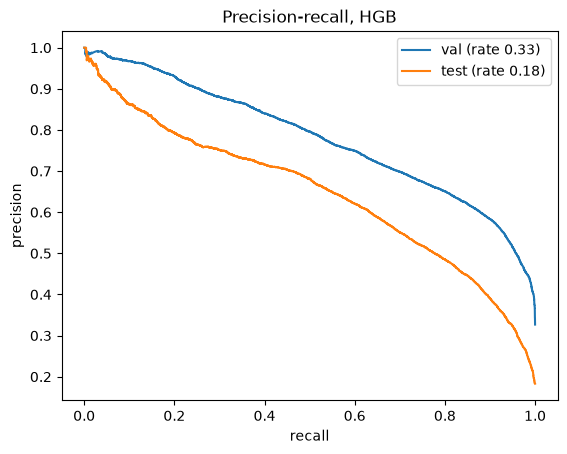

In [2]:
pr, rc, th = precision_recall_curve(va.y.values, p_va) # compute precision-recall curve on validation set
rows = []

# Compute thresholds for different target recall levels on the validation set
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    t = th[np.flatnonzero(rc[:-1] >= target)[-1]]     # highest threshold that still reaches the target recall on val
    row = dict(target_recall=target, thr=t)
    for name, d, p in [("val", va, p_va), ("test", te, p_te)]: # evaluate on both validation and test sets
        yhat = p >= t
        tp = (yhat & (d.y.values == 1)).sum() # true positives
        row |= {f"{name}_recall": tp / d.y.sum(), f"{name}_precision": tp / max(yhat.sum(), 1), # compute recall, precision, and alarm rate
                f"{name}_alarm_rate": yhat.mean()}
    rows.append(row)
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots() #Plot precision-recall curves for validation and test sets
for name, d, p in [("val", va, p_va), ("test", te, p_te)]:
    pr_, rc_, _ = precision_recall_curve(d.y.values, p)
    ax.plot(rc_, pr_, label=f"{name} (rate {d.y.mean():.2f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall, HGB"); ax.legend(); plt.show()

Considering the produced table, each row fixes a recall target on validation. It finds the threshold that hits it, then applies that same threshold to test. 

- **We can see that the operating point does not transfer**. A threshold set for 0.80 recall on val gives 0.70 on test, and 0.90 gives 0.82. The test recall is about 8-10 points lower at every setting. The direction is consistent, so it's systematic rather than noise. 
- Alarm rates are roughly hald as large on test as on validation, matching the lower dissolved rate. The model's scores adapt to the period; the fixed cutoff does not. 
- The precision-recall trade-off is steep: on test, recall 0.61 costs precision 0.62; recall 0.82 costs precision 0.47. 
- Thus, we will report operating points as validation-chosen thresholds whith their test outcomes, not as fixed recall claims. A single threshold is not transferable between periods with different dissolution rates. 


## 3. Lead Time
For a dissolved row, lead time = minutes until the cloud state first stops being cloudy. Our prediction table only holds cloudy bins, so we read it from gaps in the index: consecutive 20 s rows form a cloudy run, and the lead time is the distance to the end of that run (plus one bin). This is approximate where the first non-cloudy bin is unkown rather than clear, or where a row was dropped by the feature filter. We check this below. 

**Question:** Is the model better at endings that are imminent (0-5 min) than distant ones (10-20 min)? (We expect so, but what does this slope look like?) 

In [3]:
df = df.sort_index()
assert df.index.is_unique # ensure the DataFrame index has unique values

STEP = pd.Timedelta("20s") # define the time step for lead time calculation, 20s 
s = df.index.to_series()

run_id = (s.diff() != STEP).cumsum() # assign a unique run ID to each sequence of rows separated by the defined time step
df["lead_min"] = ((s.groupby(run_id).transform("max") - s) + STEP).dt.total_seconds() / 60 # calculate lead time in minutes for each row within its run

# recreate the fold slices so they carry lead_min, in the same row order as before
tr, va, te = (df[df.fold == k] for k in ["train", "val", "test"])
assert np.allclose(hgb.predict_proba(te[FEATURES])[:, 1], p_te) # ensure the predictions match the previously stored probabilities

# consistency: dissolved rows should end within 20 min, persisted rows should not
chk = df[df.fold.isin(["train", "val", "test"])].groupby("y").lead_min.describe().round(2)
display(chk)
print("dissolved rows with lead > 20 min:", ((df.y == 1) & (df.lead_min > 20)).mean().round(4))
print("persisted rows with lead <= 20 min:", ((df.y == 0) & (df.lead_min <= 20)).mean().round(4))

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,605468.0,541.70,750.01,0.33,94.67,273.00,667.67,5938.0
1,158675.0,7.02,5.74,0.33,2.00,5.33,11.33,20.0


dissolved rows with lead > 20 min: 0.0
persisted rows with lead <= 20 min: 0.0003


In [4]:
#Here, recall by lead time bins for dissolved rows
# Define the lead time bins and calculate recall metrics for each bin
bins_ = [0, 2, 5, 10, 20] # define the lead time bins in minutes
d = te[te.y == 1].assign(p=p_te[te.y.values == 1]) # filter for dissolved rows and assign predicted probabilities
d["lead"] = pd.cut(d.lead_min, bins_) # categorize lead times into defined bins

out = d.groupby("lead", observed=True).apply(lambda g: pd.Series(dict(
        n=len(g), mean_p=g.p.mean(), median_run_length=g.run_length_min.median(),
        recall_at_thr=(g.p >= thr).mean(), recall_at_0p44=(g.p >= 0.443).mean()))) # calculate recall metrics for each lead time bin
display(out.round(3))

,n,mean_p,median_run_length,recall_at_thr,recall_at_0p44
lead,,,,,
"(0, 2]",5650.0,0.739,3.000,0.924,0.876
"(2, 5]",4599.0,0.576,8.333,0.793,0.693
"(5, 10]",5026.0,0.481,21.667,0.677,0.554
"(10, 20]",6984.0,0.369,31.667,0.513,0.371


### Interpretation
- We see dissolved rows have lead times from 0.33 to 20.0 min, with 0.0% above 20. This is exactly what the target definition requries. 
- Only 0.03% of persisted rows have lead <= 20 min, which is negligible. The gap method seems sound. 
- Recall falls smoothly with lead time: 0.92 for endings within 2 min, 0.79 for 2--5 min, 0.68 for 5-10 min and 0.51 for 10-20 min. At the stricter 0.443 threshold the same pattern appears (0.88 down to 0.37).
- **The model is a short-range detector.** It catches imminent endings well and distant ones about half the time. 
- Lead time is entangled with cloud age (median age rises from 3 to 32 min across the bins), so part of the decline reflects the model treating older clouds as persistent. Lead time near 20 min is also close to the label boundary, where a cloud ending at 19 min and one ending at 21 min look alike at time t, limiting how well any model can do there. 
- **Implication:** the horizon matters. A shorter horizon (5 or 10 min) should score better, and the 20 min results reflect a long forecast range. 

## 4. Long Clouds
`09_modeling.ipynb` showed PR-AUC 0.29 and recall 0.27 for clouds older than 60 min (68% of test rows). 

**Question:** Is that a fitting limit (the pooled model underfits old clouds) or a feature limit (cloud-state history carries little signal for them)?

Here, we will fit a model on old clouds and compare it with the pooled model on the same rows. 

In [5]:
OLD = 60 # define the threshold for old run lengths in minutes, 60. 
tr_o, va_o, te_o = (d[d.run_length_min > OLD] for d in (tr, va, te)) # filter for old runs based on the defined threshold
print({k: (len(d), round(d.y.mean(), 3)) for k, d in [("train", tr_o), ("val", va_o), ("test", te_o)]})

# Train a specialized model on old runs only and evaluate against validation and test sets of old runs
spec = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300,
                                      early_stopping=True, validation_fraction=0.1, random_state=0) #Different random state
spec.fit(tr_o[FEATURES], tr_o.y) #Fit!

rows = []
for name, d in [("val", va_o), ("test", te_o)]: # iterate over validation and test sets of old runs
    p_pool = hgb.predict_proba(d[FEATURES])[:, 1] # predictions from the pooled model
    p_spec = spec.predict_proba(d[FEATURES])[:, 1] # predictions from the specialized old-only model
    for model, p in [("pooled", p_pool), ("old_only", p_spec)]:
        rows.append(dict(fold=name, model=model, n=len(d), rate=d.y.mean(),
                         pr_auc=average_precision_score(d.y, p), roc_auc=roc_auc_score(d.y, p)))
display(pd.DataFrame(rows).round(3))

{'train': (384674, np.float64(0.06)), 'val': (38415, np.float64(0.092)), 'test': (82876, np.float64(0.062))}


,fold,model,n,rate,pr_auc,roc_auc
0,val,pooled,38415,0.092,0.341,0.834
1,val,old_only,38415,0.092,0.347,0.825
2,test,pooled,82876,0.062,0.293,0.818
3,test,old_only,82876,0.062,0.265,0.811


### Interpretation
Our result is clear: a model trained only on old clouds does **not** beat the pooled model. That points to a feature limit, not a fitting limit. 

- Clouds older than 60 min are the majority of test rows (82,876, 68%) but rarely dissolve within 20 min (6.2% on test, 9.2% on val, 6.0% on train). 
- A model trained only on old clouds does not beat the pooled model on those rows: val PR-AUC 0.347 vs 0.341, test 0.265 vs 0.293, ROC-AUC lower in both. Specializing does not help. 
- The pooled model still has real skill here (test PR-AUC 0.293 against a no-skill 0.062, about 4.7x; ROC-AUC 0.82), but precision is low becuase positives are rare. 
- **Therefore:** The weakness on old clouds is a feature limit, not a fitting limit. 

## 5. Feature-group Importance
Permutation importance by group on validation: Here we will shuffle all columns in a group together and measure the drop in PR-AUC. A larger drop means the model relies more on that group. We will do this for all rows and for old clouds (> 60 min) separately. 

,all_val,old_val
structure,0.230,0.236
cloud_fraction,0.090,0.009
run_length,0.048,0.005
time_of_day,0.014,0.003
availability,0.000,0.000


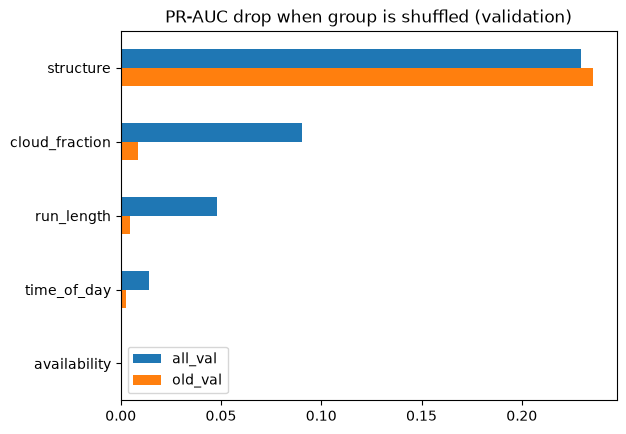

In [6]:
GROUPS = { #Redefine feature groups for importance analysis
    "run_length": ["run_length_min"],
    "cloud_fraction": [c for c in FEATURES if c.startswith(("cloud_fraction", "cf_", "n_flips"))],
    "structure": ["n_layers_mean", "lowest_base_m", "highest_top_m", "vertical_span_m",
                  "lowest_base_change_5min", "highest_top_change_5min"],
    "availability": ["kazr_avail_frac"],
    "time_of_day": ["hour_sin", "hour_cos"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES) # ensure all features are accounted for in the groups

#Here, a function to calculate feature group importance based on PR-AUC drop when the group's values are shuffled (permutation importance)
def group_importance(model, d, n_repeats=5, seed=0):
    rng = np.random.default_rng(seed) # initialize random number generator with the given seed
    base = average_precision_score(d.y, model.predict_proba(d[FEATURES])[:, 1]) # calculate the baseline PR-AUC without shuffling
    out = {}
    for g, cols in GROUPS.items(): # iterate over each feature group
        drops = []
        for _ in range(n_repeats):
            x = d[FEATURES].copy()
            x[cols] = x[cols].iloc[rng.permutation(len(x))].values   # shuffle the group's rows together to break any association with the target
            drops.append(base - average_precision_score(d.y, model.predict_proba(x)[:, 1])) # calculate the drop in PR-AUC after shuffling
        out[g] = np.mean(drops)
    return pd.Series(out)

imp = pd.DataFrame({"all_val": group_importance(hgb, va),
                    "old_val": group_importance(hgb, va_o)}).sort_values("all_val", ascending=False)
display(imp.round(3))
imp.plot.barh(title="PR-AUC drop when group is shuffled (validation)"); plt.gca().invert_yaxis(); plt.show()

### Interpretation
There is many important findings here, some of which change our interpretations about previous steps. 

- Verticle structure is the most important group by a wide margin: shuffling it drops validation PR-AUC by 0.230 (0.781 -> ~0.55). Cloud-fraction history (0.090) and run length (0.048) follow. 
- For old clouds, strcture accounts for nearly all the skill: the drop is 0.236 from a PR-AUC of 0.341, leaving about 0.10, close to the no-skill rate of 0.092. 
- Run length ranks low inside the boosted model even though it is a strong baseline alone, because other features carry overlapping information; permutation importance understates features with substitutes. 
- Availability and time of day contribute nothing. 
- Adding / revision to step 4: the weakness on old clouds is a limit of cloud-fraction and age features, not of the whole feature set. Vertical structure is where the signal lies, which motivates richer vertical information (radar reflectivity and Doppler profiles). 
- **Caveats:** Importance shows reliance, not causation; structure may partly stand in for cloud type or season, which may not transfer to other years. 

### Which structured features contribute? 

In [7]:
SPLIT = {"static_structure": ["n_layers_mean", "lowest_base_m", "highest_top_m", "vertical_span_m"],
         "change_5min": ["lowest_base_change_5min", "highest_top_change_5min"],
         "base_m": ["lowest_base_m"], "top_m": ["highest_top_m"], "span_m": ["vertical_span_m"]}

GROUPS_BAK = GROUPS # backup the original groups before splitting
GROUPS = SPLIT # temporarily replace the groups with the split groups
imp2 = pd.DataFrame({"all_val": group_importance(hgb, va), "old_val": group_importance(hgb, va_o)}) # calculate importance with split groups
GROUPS = GROUPS_BAK # restore the original groups
display(imp2.round(3))

,all_val,old_val
static_structure,0.229,0.234
change_5min,0.009,0.028
base_m,0.021,0.085
top_m,0.027,0.036
span_m,0.163,0.217


We see that `span_m` (0.163 all, 0.217 old) carries almost all of the structure importance. Cloud thickness is the dominant signal. Furthermore, its important to note that the parts don't sum to 0.230, since the features are correlated and share credit. This will motivate notebook 11. 

## Conclusion & Next Steps
**Conclusion:** The 20 min Persistence model is a short-range detector. It catches imminent endings (recall 0.92 within 2 min, 0.51 at 10-20 min) and young clouds, and is weak on clouds older than 60 min. A model specialized for old clouds does not help. Vertical structure carries most of the skill, especially for old clouds. 

**Operating points:** A validation-chosen threshold loses 8-10 points of recall on test because the dissolved rate differs between periods; we should report thresholds with their test outcomes. 

**Caveats:** One year and site; lead time is entangled with cloud age; structure may proxy cloud type or season; permutation importance reflects reliance, not causation. 

**Next Steps:**
1. Notebook 11: Build radar profile features (reflectivity and Doppler statistics by layer), after settling the clutter-mask and SNR policy, and test whether they lift old-cloud PR-AUC above 0.29. 
2. Horizon sensitivity (5 min, 1 h) and the "N consecutive clear bins" definition. 
3. Freeze `src/modeling.py` once the feature set is settled. 